In [1]:

import os
import json
import joblib
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

from pathlib import Path

INPUT_DIR = Path("/kaggle/input")

# Find Excel files
excel_files = list(INPUT_DIR.rglob("*.xlsx"))

print("Available Excel files:\n")

for file in excel_files:
    print(file)

if not excel_files:
    raise FileNotFoundError(
        "No Excel files found in Kaggle input."
    )


Available Excel files:

/kaggle/input/datasets/muratkokludataset/dry-bean-dataset/Dry_Bean_Dataset/Dry_Bean_Dataset.xlsx


In [3]:

# Find the Dry Bean Excel file
dataset_path = next(
    (
        file for file in excel_files
        if "dry_bean_dataset.xlsx" in file.name.lower()
    ),
    None
)

if dataset_path is None:
    raise FileNotFoundError(
        "Dry_Bean_Dataset.xlsx was not found."
    )

# Inspect available sheets
excel_data = pd.ExcelFile(dataset_path)

print("Available Sheets:")
print(excel_data.sheet_names)

# Load the actual dataset sheet
df = pd.read_excel(
    dataset_path,
    sheet_name="Dry_Beans_Dataset"
)

# Identify target column
target_column = next(
    (
        col for col in df.columns
        if str(col).strip().lower() == "class"
    ),
    None
)

if target_column is None:
    raise ValueError("Target column 'Class' not found.")

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Target column:", target_column)

display(df.head())


Available Sheets:
['Dry_Beans_Dataset', 'Citation_Request']

Dataset loaded successfully!
Dataset shape: (13611, 17)
Target column: Class


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [4]:

print("Dataset Information:")
print("-" * 50)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nStatistical Summary:")
display(df.describe().T)


Dataset Information:
--------------------------------------------------

First 5 Rows:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER



Dataset Shape:
(13611, 17)

Column Names:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']

Data Types:
Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRation       float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class               object
dtype: object

Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRation,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


In [5]:

print("Missing Values:")
display(df.isnull().sum().to_frame("Missing Count"))

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nUnique Values per Column:")
display(df.nunique().to_frame("Unique Values"))

print("\nClass Distribution:")
display(df[target_column].value_counts().to_frame("Count"))


Missing Values:


,Missing Count
Area,0
Perimeter,0
MajorAxisLength,0
MinorAxisLength,0
AspectRation,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Solidity,0



Total Missing Values:
0

Duplicate Rows:
68

Unique Values per Column:


,Unique Values
Area,12011
Perimeter,13416
MajorAxisLength,13543
MinorAxisLength,13543
AspectRation,13543
Eccentricity,13543
ConvexArea,12066
EquivDiameter,12011
Extent,13535
Solidity,13526



Class Distribution:


,Count
Class,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1928
CALI,1630
BARBUNYA,1322
BOMBAY,522


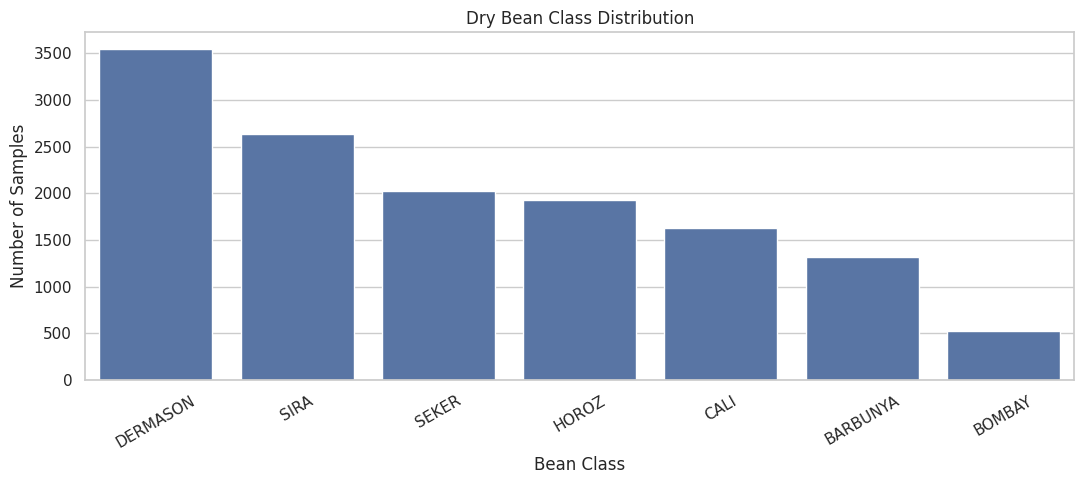

Number of Classes: 7


,Count,Percentage
Class,,
DERMASON,3546,26.05
SIRA,2636,19.37
SEKER,2027,14.89
HOROZ,1928,14.17
CALI,1630,11.98
BARBUNYA,1322,9.71
BOMBAY,522,3.84


In [6]:

class_counts = df[target_column].value_counts()

plt.figure(figsize=(11, 5))

sns.countplot(
    data=df,
    x=target_column,
    order=class_counts.index
)

plt.title("Dry Bean Class Distribution")
plt.xlabel("Bean Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

print("Number of Classes:", df[target_column].nunique())

display(
    pd.DataFrame({
        "Count": class_counts,
        "Percentage": (class_counts / len(df) * 100).round(2)
    })
)


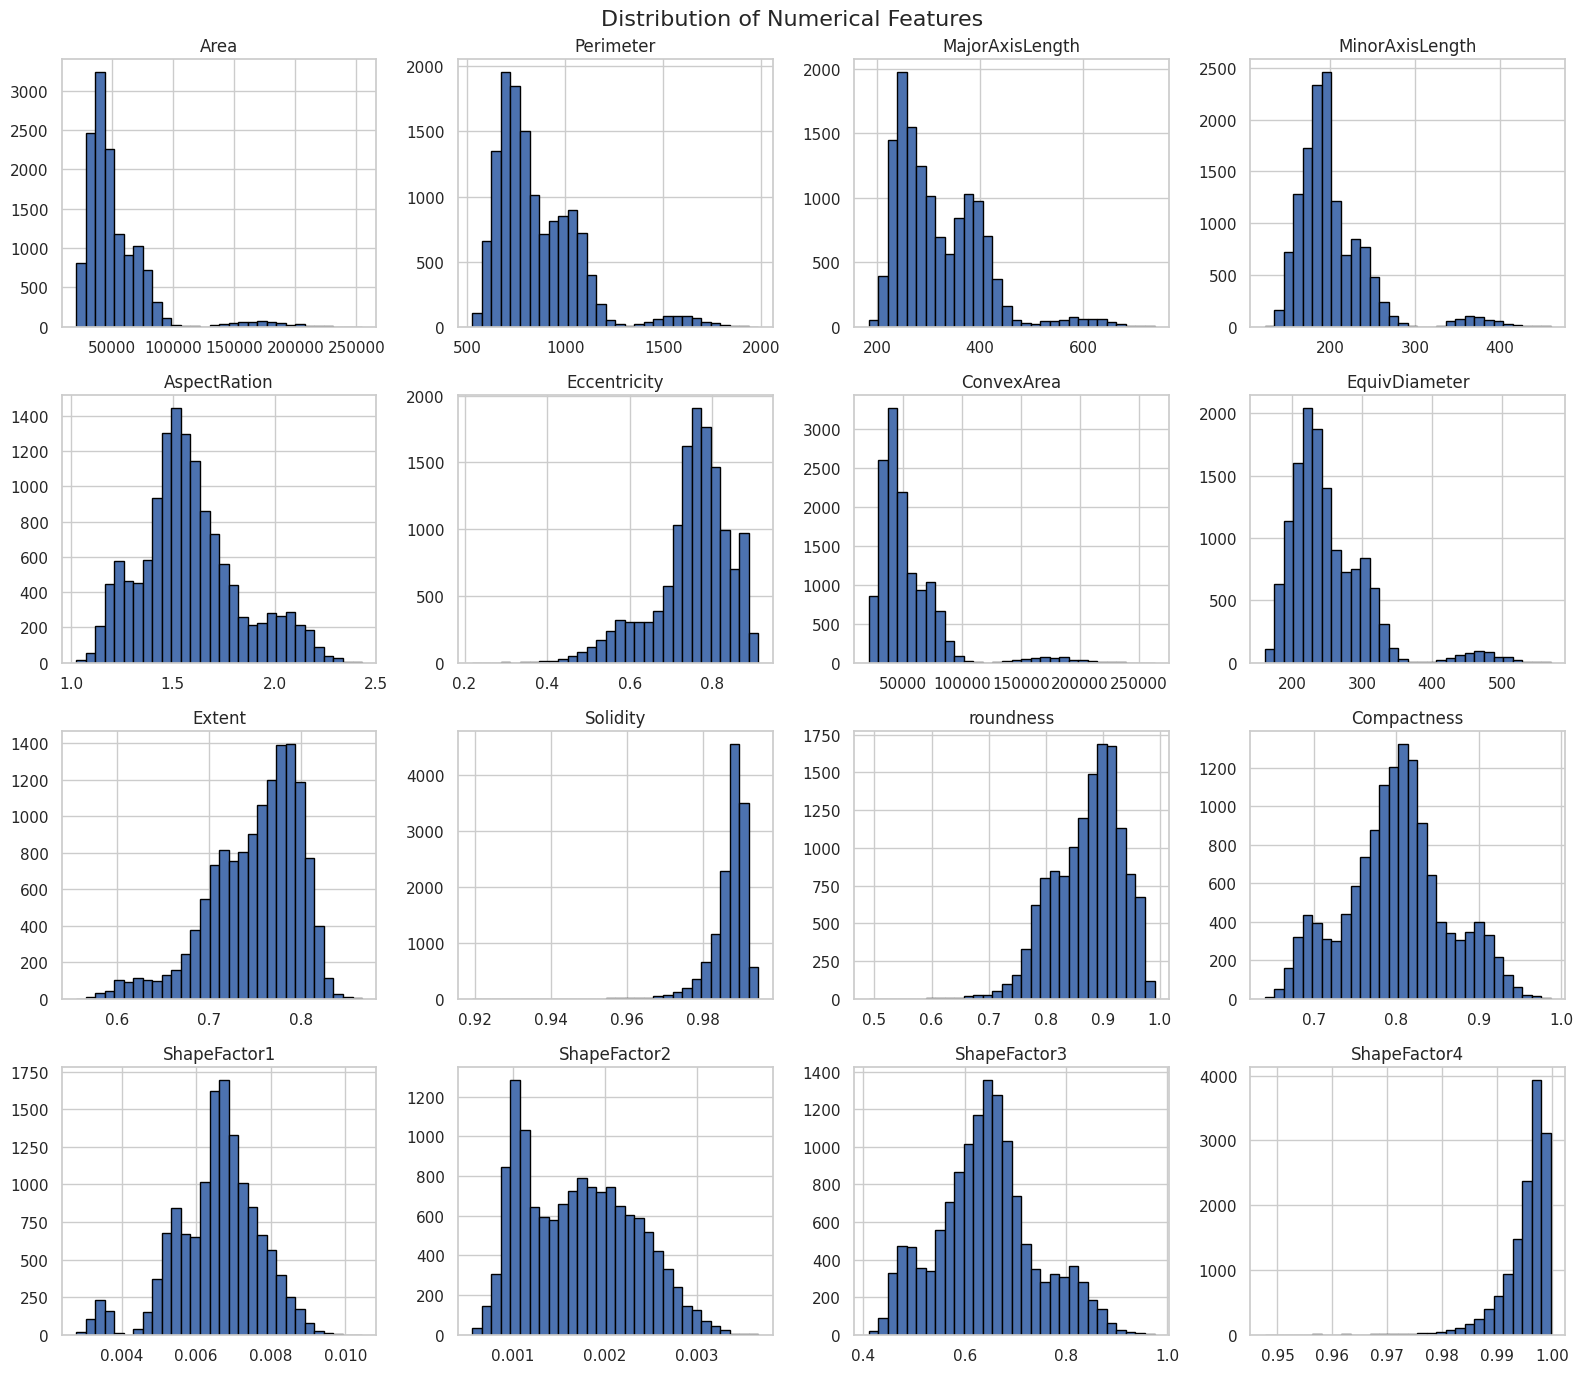

In [7]:

feature_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

if target_column in feature_columns:
    feature_columns.remove(target_column)

df[feature_columns].hist(
    figsize=(16, 14),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()


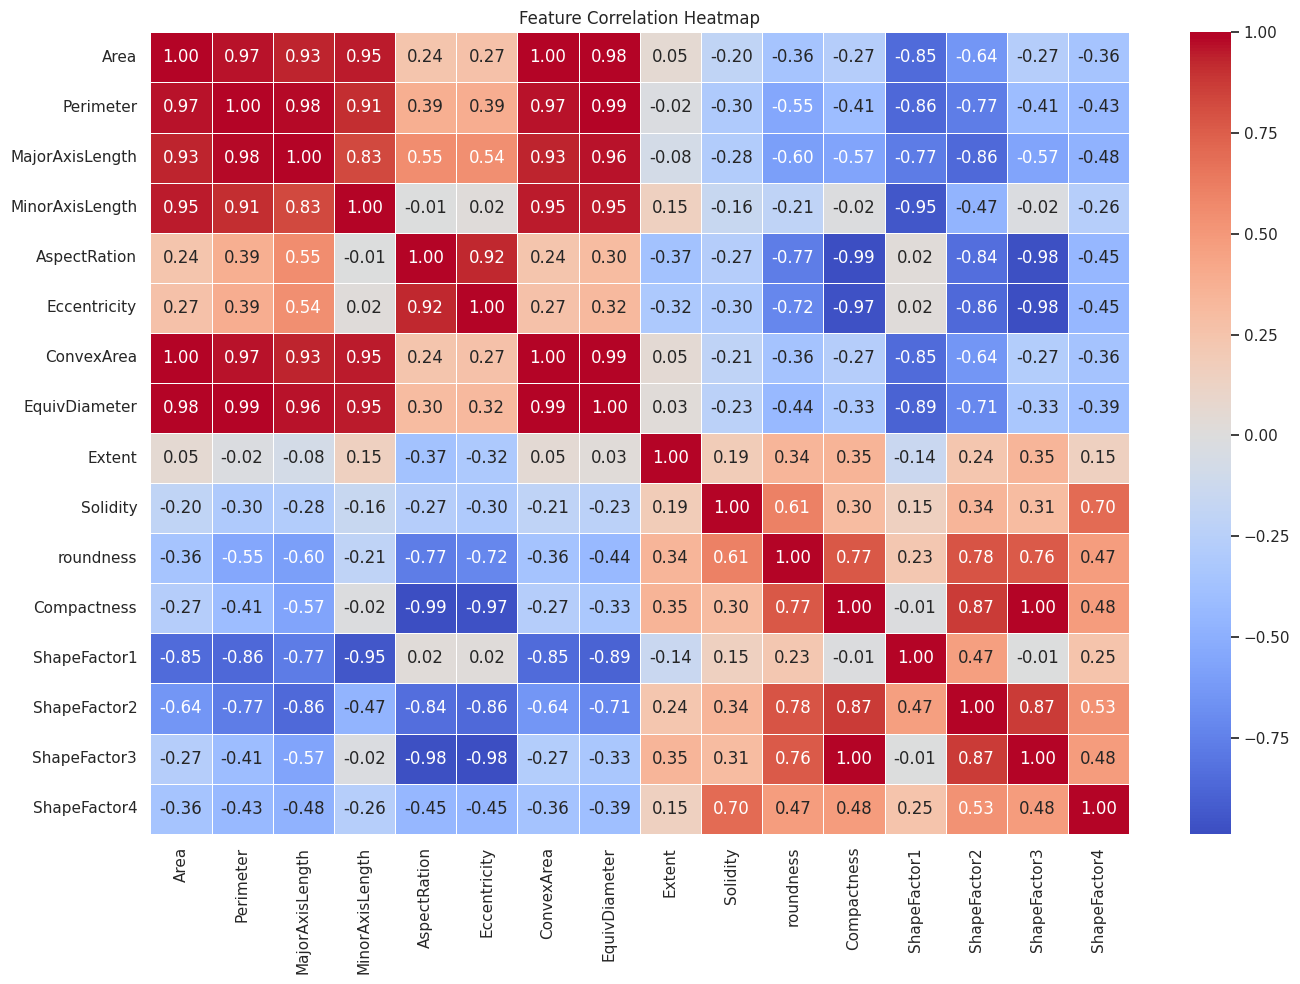

In [8]:

correlation_matrix = df[feature_columns].corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


In [9]:

print("Dataset shape before removing duplicates:", df.shape)

duplicate_count = df.duplicated().sum()

print("Duplicate records found:", duplicate_count)

df = df.drop_duplicates().reset_index(drop=True)

print("\nDataset shape after removing duplicates:", df.shape)

print("Remaining duplicates:", df.duplicated().sum())

print("\nUpdated class distribution:")
display(df[target_column].value_counts())

print("\nDuplicate removal completed!")


Dataset shape before removing duplicates: (13611, 17)
Duplicate records found: 68

Dataset shape after removing duplicates: (13543, 17)
Remaining duplicates: 0

Updated class distribution:


Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1860
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


Duplicate removal completed!


In [10]:

# Separate target
y = df[target_column].copy()

# Remove target from features
X = df.drop(columns=[target_column]).copy()

# Remove identifier columns if present
id_columns = [
    col for col in X.columns
    if str(col).strip().lower() in [
        "id", "index", "unnamed: 0"
    ]
]

if id_columns:
    X = X.drop(columns=id_columns)

print("Identifier columns removed:", id_columns)

# Verify feature types
non_numeric_columns = X.select_dtypes(
    exclude=np.number
).columns.tolist()

if non_numeric_columns:
    raise ValueError(
        f"Unexpected non-numeric features: {non_numeric_columns}"
    )

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nClasses:")
print(sorted(y.unique().tolist()))


Identifier columns removed: []

Features Shape: (13543, 16)
Target Shape: (13543,)

Features:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']

Classes:
['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


In [11]:

# Encode target labels
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_encoded
)

print("Train-Test Split Completed!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

# Handle missing values
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("\nPreprocessing Completed!")
print("Training data standardized.")
print("Testing data standardized.")

print("\nEncoded Classes:")
for index, class_name in enumerate(label_encoder.classes_):
    print(f"{index}: {class_name}")


Train-Test Split Completed!
X_train: (10834, 16)
X_test: (2709, 16)
y_train: (10834,)
y_test: (2709,)

Preprocessing Completed!
Training data standardized.
Testing data standardized.

Encoded Classes:
0: BARBUNYA
1: BOMBAY
2: CALI
3: DERMASON
4: HOROZ
5: SEKER
6: SIRA


In [12]:

print("Final Dataset Validation")
print("=" * 50)

print("Training Samples:", len(X_train_scaled))
print("Testing Samples:", len(X_test_scaled))

print("Number of Features:", X_train_scaled.shape[1])
print("Number of Classes:", len(label_encoder.classes_))

print("\nTraining Class Distribution:")
display(
    pd.Series(y_train).value_counts().sort_index().to_frame("Count")
)

print("\nTesting Class Distribution:")
display(
    pd.Series(y_test).value_counts().sort_index().to_frame("Count")
)

print("\nTraining Feature Means (should be near zero):")
print(np.round(X_train_scaled.mean(axis=0), 4))

print("\nTraining Feature Standard Deviations (should be near one):")
print(np.round(X_train_scaled.std(axis=0), 4))

assert not np.isnan(X_train_scaled).any()
assert not np.isnan(X_test_scaled).any()

print("\nAll validation checks passed!")


Final Dataset Validation
Training Samples: 10834
Testing Samples: 2709
Number of Features: 16
Number of Classes: 7

Training Class Distribution:


,Count
0,1057
1,418
2,1304
3,2837
4,1488
5,1621
6,2109



Testing Class Distribution:


,Count
0,265
1,104
2,326
3,709
4,372
5,406
6,527



Training Feature Means (should be near zero):
[-0.  0. -0. -0.  0.  0.  0. -0. -0. -0. -0.  0.  0.  0. -0. -0.]

Training Feature Standard Deviations (should be near one):
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

All validation checks passed!


In [13]:

OUTPUT_DIR = Path("/kaggle/working/dry_bean_processed")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save scaled features
pd.DataFrame(
    X_train_scaled,
    columns=X.columns
).to_csv(
    OUTPUT_DIR / "X_train_scaled.csv",
    index=False
)

pd.DataFrame(
    X_test_scaled,
    columns=X.columns
).to_csv(
    OUTPUT_DIR / "X_test_scaled.csv",
    index=False
)

# Save target labels
pd.DataFrame({
    "target": y_train
}).to_csv(
    OUTPUT_DIR / "y_train.csv",
    index=False
)

pd.DataFrame({
    "target": y_test
}).to_csv(
    OUTPUT_DIR / "y_test.csv",
    index=False
)

# Save preprocessing objects
joblib.dump(scaler, OUTPUT_DIR / "scaler.pkl")
joblib.dump(imputer, OUTPUT_DIR / "imputer.pkl")
joblib.dump(label_encoder, OUTPUT_DIR / "label_encoder.pkl")

# Save metadata
metadata = {
    "dataset": "Dry Bean Dataset",
    "target_column": target_column,
    "feature_names": X.columns.tolist(),
    "classes": label_encoder.classes_.tolist(),
    "number_of_classes": len(label_encoder.classes_),
    "number_of_features": X.shape[1],
    "train_samples": len(X_train_scaled),
    "test_samples": len(X_test_scaled),
    "test_size": 0.20,
    "random_state": RANDOM_STATE
}

with open(OUTPUT_DIR / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

# Save NumPy versions for faster loading
np.save(OUTPUT_DIR / "X_train_scaled.npy", X_train_scaled)
np.save(OUTPUT_DIR / "X_test_scaled.npy", X_test_scaled)
np.save(OUTPUT_DIR / "y_train.npy", y_train)
np.save(OUTPUT_DIR / "y_test.npy", y_test)

print("All processed files saved successfully!")

# Create ZIP archive
ZIP_PATH = "/kaggle/working/dry_bean_processed.zip"

with zipfile.ZipFile(
    ZIP_PATH, "w", zipfile.ZIP_DEFLATED
) as zipf:

    for file in OUTPUT_DIR.iterdir():
        zipf.write(file, arcname=file.name)

print("\nZIP archive created:")
print(ZIP_PATH)

print("\nSaved files:")
for file in OUTPUT_DIR.iterdir():
    print(file.name)


All processed files saved successfully!

ZIP archive created:
/kaggle/working/dry_bean_processed.zip

Saved files:
X_train_scaled.csv
y_train.csv
scaler.pkl
X_test_scaled.csv
y_test.npy
y_test.csv
X_test_scaled.npy
imputer.pkl
metadata.json
label_encoder.pkl
X_train_scaled.npy
y_train.npy
